# Task 3 — GRPO (ATML PA2)
Runtime → Change runtime type → **GPU**. Run cells top to bottom.

**Disconnect-safe:** `outputs/` and `results/` are symlinked to Google Drive (`MyDrive/ATML_PA2_task3`); finished runs/evals are detected and skipped on re-run.

Pipeline: validate → smoke test → standard 20-update GRPO continuation → held-out evals → equal-generation group-size study (K=2,4,8; no training) → canonical vs Dr.-GRPO forks (+ length-conditioned gradient statistics) → tables/plots → qualitative examples.

**All hyper-parameters come from the release `configs/grpo.yaml` / `base.yaml` (no overrides, no code-side defaults).**

In [ ]:
%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
!nvidia-smi | head -15
import os
if not os.path.isdir('/content/ATML-PA2-LLM-PostTraining'):
    !git clone https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
%cd /content/ATML-PA2-LLM-PostTraining

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
Tue Oct 13 15:59:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
D='/content/drive/MyDrive/ATML_PA2_task3'
for n in ('outputs','results'):
    os.makedirs(f'{D}/{n}',exist_ok=True)
    if os.path.islink(n): os.remove(n)                     # re-point (a previous task may have linked it elsewhere)
    elif os.path.isdir(n): os.system(f'rm -rf {n}')
    os.symlink(f'{D}/{n}',n)
!ls -la outputs results

Mounted at /content/drive
lrwxrwxrwx 1 root root 45 Oct 13 15:59 outputs -> /content/drive/MyDrive/ATML_PA2_task3/outputs
lrwxrwxrwx 1 root root 45 Oct 13 15:59 results -> /content/drive/MyDrive/ATML_PA2_task3/results


In [ ]:
!pip install -q -r requirements.txt
!python -m scripts.download_assets
!python -m scripts.validate_assets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Source: AbDu11aHHH/ATML-PA2-assets
Revis

## Student code
- **GRPO objective fix** (`grpo.py`): the starter's `group_relative_advantages` standardised over the **whole batch** and ignored `group_ids`. It now standardises **within each prompt group**: `A = (r − μ_g) / (σ_g + ε)`.
- `grpo_loss_parts` exposes the differentiable policy term and KL separately, so a group can be back-propagated one completion at a time with the exact same total loss (checked by a unit test).
- Canonical GRPO divides each completion by its length T_k; Dr.-GRPO by the constant `max_completion_length`.
- Max-length (truncated) completions are masked from the loss (`mask_truncated_completions`), but still count in the group reward statistics.
- Trainable LoRA weights in fp32 (+ fp16 autocast, `GradScaler`) — fp16 AdamW states underflow to NaN. Non-finite loss raises immediately.
- Dropout (incl. LoRA dropout) off during the update so π_θ = π_old at the first epoch. Reference policy = base model (adapter disabled).
- Per-completion logs (`seqstats_*.jsonl`: length, reward, advantage, per-token weight, **per-completion gradient norm**) support the length-conditioned analysis.

In [ ]:
%%writefile task3_grpo/__init__.py


Overwriting task3_grpo/__init__.py


In [ ]:
%%writefile task3_grpo/grpo.py
from __future__ import annotations

import torch

from common.metrics import masked_mean, sample_entropy

# Epsilon of the group-relative advantage A = (r - mu) / (sigma + eps)  (same value as the starter's default).
# A group is "uninformative" when its reward std is <= this value (advantages are then exactly 0).
ADV_EPS = 1e-6


def group_relative_advantages(rewards: torch.Tensor, group_ids: torch.Tensor, eps: float = ADV_EPS):
    """One scalar advantage per sampled completion, standardised *within its own prompt group*.

    A_k = (r_k - mu_g) / (sigma_g + eps),  mu_g, sigma_g = mean / (population) std of the rewards of group g.
    (The starter standardised over the whole batch, ignoring `group_ids`; that is not GRPO.)
    """
    rewards = rewards.float()
    adv = torch.zeros_like(rewards)
    for g in torch.unique(group_ids):
        m = group_ids == g
        r = rewards[m]
        adv[m] = (r - r.mean()) / (r.std(unbiased=False) + eps)
    return adv


def group_reward_stats(rewards: torch.Tensor, group_ids: torch.Tensor, eps: float = ADV_EPS):
    """Per-group reward std and the informative flag (std > eps)."""
    stds = []
    for g in torch.unique(group_ids):
        stds.append(rewards[group_ids == g].float().std(unbiased=False))
    stds = torch.stack(stds)
    return stds, stds > eps


def grpo_loss_parts(new_logp, old_logp, seq_adv, token_mask, ref_logp, eps,
                    loss_type="grpo", max_completion_length: int | None = None):
    """Differentiable (policy_term, kl) of the GRPO loss plus detached diagnostics.

    policy_term = -mean_k [ sum_t min(rho A, clip(rho) A) * mask / norm_k ]
      grpo   : norm_k = T_k (realised, unmasked length)          -> 1/T_k sequence normalisation
      dr_grpo: norm_k = max_completion_length (a constant)       -> no length dependence
    kl = masked mean over all unmasked tokens of the k3 estimator  exp(ref-new) - (ref-new) - 1.
    """
    ratio = torch.exp(new_logp - old_logp)
    adv = seq_adv[:, None]
    s1 = ratio * adv
    s2 = ratio.clamp(1.0 - eps, 1.0 + eps) * adv
    objective = torch.minimum(s1, s2)

    token_sum = (objective * token_mask).sum(-1)
    if loss_type == "grpo":
        per_sequence = token_sum / token_mask.sum(-1).clamp_min(1.0)
    elif loss_type == "dr_grpo":
        if max_completion_length is None:
            raise ValueError("dr_grpo requires max_completion_length")
        per_sequence = token_sum / float(max_completion_length)
    else:
        raise ValueError(f"Unknown loss_type={loss_type!r}")
    policy_term = -per_sequence.mean()

    log_ratio_ref_over_policy = ref_logp - new_logp
    per_token_kl = torch.exp(log_ratio_ref_over_policy) - log_ratio_ref_over_policy - 1.0
    kl = masked_mean(per_token_kl, token_mask)

    affected = ((ratio < (1.0 - eps)) | (ratio > (1.0 + eps))).float()
    diag = {
        "policy_term": policy_term.detach(),
        "sampled_kl": kl.detach(),
        "clip_fraction": masked_mean(affected, token_mask).detach(),
        "ratio_mean": masked_mean(ratio.detach(), token_mask),
        "sample_entropy": sample_entropy(new_logp.detach(), token_mask),
    }
    return policy_term, kl, diag


def grpo_policy_loss(new_logp, old_logp, seq_adv, token_mask, ref_logp, eps, beta,
                     loss_type="grpo", max_completion_length: int | None = None):
    """PPO-style clipped GRPO loss for already-sampled completions: policy_term + beta * KL.

    `token_mask` is all-zero for a completion deliberately masked because it hit the maximum length.
    """
    policy_term, kl, diag = grpo_loss_parts(new_logp, old_logp, seq_adv, token_mask, ref_logp, eps,
                                            loss_type, max_completion_length)
    return policy_term + float(beta) * kl, diag


def mask_truncated_sequences(token_mask: torch.Tensor, truncated: list[bool] | torch.Tensor):
    truncated = torch.as_tensor(truncated, device=token_mask.device, dtype=torch.bool)
    keep = (~truncated).to(token_mask.dtype)[:, None]
    return token_mask * keep


Overwriting task3_grpo/grpo.py


In [ ]:
%%writefile task3_grpo/utils.py
from __future__ import annotations

import torch

from common.generation import batch_generate


def filter_prompts(tokenizer, rows, max_prompt_length):
    """Deterministically skip prompts longer than max_prompt_length (no truncation)."""
    from common.data import prompt_messages
    kept, skipped = [], []
    for i, row in enumerate(rows):
        ids = tokenizer.apply_chat_template(prompt_messages(row), tokenize=True, add_generation_prompt=True)
        if not isinstance(ids, list):
            ids = ids["input_ids"]
        (kept if len(ids) <= max_prompt_length else skipped).append(i)
    return kept, skipped


def set_train_no_dropout(model):
    """Train mode with every Dropout (incl. LoRA dropout) off, so pi_theta == pi_old at the first epoch."""
    model.train()
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.eval()


def trainable_to_fp32(model):
    """fp32 master weights for trainable params (fp16 AdamW states underflow -> NaN)."""
    for p in model.parameters():
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.float()
    return model


def _autocast(device):
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda")


def generate_rollout(model, tok, prompts, cfg, max_new):
    g = cfg["generation"]
    prev = model.config.use_cache
    model.eval()
    model.config.use_cache = True
    try:
        gen = batch_generate(model, tok, prompts, int(cfg["max_prompt_length"]), max_new,
                             g["temperature"], g["top_p"], g["do_sample"])
        return {k: (v.detach().clone() if torch.is_tensor(v) else v) for k, v in gen.items()}
    finally:
        model.config.use_cache = prev


def response_logprobs(model, sequences, attention_mask, prompt_width, response_ids,
                      grad=False, entropy=False, chunk_size=1):
    """Log-prob of each response token (and optionally the full-distribution entropy). Returns [B, W]."""
    W = response_ids.shape[1]
    assert sequences.shape[1] == prompt_width + W, "sequences must be prompt_width + response width"
    lps, ents = [], []
    for s in range(0, sequences.shape[0], chunk_size):
        e = min(s + chunk_size, sequences.shape[0])
        with torch.set_grad_enabled(grad), _autocast(sequences.device):
            out = model(input_ids=sequences[s:e], attention_mask=attention_mask[s:e],
                        use_cache=False, return_dict=True, logits_to_keep=W + 1)
        logits = out.logits[:, :-1, :].float()
        del out
        logp = torch.log_softmax(logits, dim=-1)
        del logits
        lps.append(logp.gather(-1, response_ids[s:e].unsqueeze(-1)).squeeze(-1))
        if entropy:
            with torch.no_grad():
                ents.append(-(logp.exp() * logp).sum(-1))
        del logp
    return torch.cat(lps, 0), (torch.cat(ents, 0) if entropy else None)


def optimizer_step(scaler, opt, params, max_grad_norm):
    """Unscale, clip, step (the scaler skips the step on inf/nan grads). Returns (grad_norm, stepped)."""
    scaler.unscale_(opt)
    gn = torch.nn.utils.clip_grad_norm_(params, max_grad_norm)
    before = scaler.get_scale()
    scaler.step(opt)
    scaler.update()
    opt.zero_grad(set_to_none=True)
    return float(gn), bool(scaler.get_scale() >= before)


Writing task3_grpo/utils.py


In [ ]:
%%writefile task3_grpo/continue_train.py
from __future__ import annotations

import argparse
import json
import math
import time

import torch
from torch.optim import AdamW

from common.data import load_yaml, prompt_messages, read_jsonl, repo_path
from common.generation import score_reward_pairs
from common.logging_utils import append_jsonl, set_seed
from common.metrics import masked_mean
from common.models import (clear_gpu, load_policy, load_reward_model, load_tokenizer, reference_mode,
                           trainable_parameters)
from task3_grpo.grpo import (ADV_EPS, group_relative_advantages, group_reward_stats, grpo_loss_parts,
                             mask_truncated_sequences)
from task3_grpo.utils import (filter_prompts, generate_rollout, optimizer_step, response_logprobs,
                              set_train_no_dropout, trainable_to_fp32)

MAX_SKIPPED_STEP_RETRIES = 10  # GradScaler overflow retries of the *same* batch before giving up


def prepare_grpo_continuation(config_path: str):
    cfg = load_yaml(config_path)
    set_seed(int(cfg["seed"]))
    tokenizer = load_tokenizer(cfg["base_model"])
    policy = trainable_to_fp32(load_policy(cfg, adapter_path=cfg["paths"]["grpo_midpoint_policy"], trainable=True))
    reward_model, reward_tokenizer = load_reward_model(cfg)
    prompts = read_jsonl(cfg["paths"]["rl_prompt_train"])
    optimizer = AdamW(trainable_parameters(policy), lr=float(cfg["learning_rate"]))
    return {"cfg": cfg, "tokenizer": tokenizer, "policy": policy, "reward_model": reward_model,
            "reward_tokenizer": reward_tokenizer, "prompt_rows": prompts, "optimizer": optimizer}


def run_grpo(config_path: str, output: str | None = None, updates: int | None = None,
             loss_type: str = "grpo", run_name: str = "standard"):
    bundle = prepare_grpo_continuation(config_path)
    cfg, tok, policy, opt = bundle["cfg"], bundle["tokenizer"], bundle["policy"], bundle["optimizer"]
    rm, rtok, prompt_pool = bundle["reward_model"], bundle["reward_tokenizer"], bundle["prompt_rows"]
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    updates = int(updates) if updates is not None else int(cfg["updates"])
    out = repo_path(output or cfg["output"])
    out.mkdir(parents=True, exist_ok=True)

    K = int(cfg["num_generations"])
    prompts_per_update = int(cfg["prompts_per_update"])
    policy_epochs = int(cfg["policy_epochs"])
    eps, beta = float(cfg["clip_epsilon"]), float(cfg["kl_beta"])
    max_len = int(cfg["max_completion_length"])
    mask_trunc = bool(cfg["mask_truncated_completions"])
    max_grad_norm = float(cfg["max_grad_norm"])
    params = trainable_parameters(policy)
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")

    kept, skipped = filter_prompts(tok, prompt_pool, int(cfg["max_prompt_length"]))
    print(f"[{run_name}] loss_type={loss_type} | K={K} | prompts/update={prompts_per_update} | "
          f"epochs={policy_epochs} | kept prompts {len(kept)}, skipped {len(skipped)}")

    results = repo_path(cfg["results_dir"])
    results.mkdir(parents=True, exist_ok=True)
    log_path, seq_path = results / f"train_log_{run_name}.jsonl", results / f"seqstats_{run_name}.jsonl"
    for p in (log_path, seq_path):
        if p.exists():
            p.unlink()

    if dev.type == "cuda":
        torch.cuda.reset_peak_memory_stats(dev)
    start, prompt_idx, total_gen_tokens = time.time(), 0, 0

    for u in range(1, updates + 1):
        t0 = time.time()

        # 1. prompts -> K completions each (group_ids identify the prompt of every completion) -----------
        batch_msgs, group_ids = [], []
        for g in range(prompts_per_update):
            msgs = prompt_messages(prompt_pool[kept[prompt_idx % len(kept)]])
            prompt_idx += 1
            batch_msgs += [msgs] * K
            group_ids += [g] * K
        group_ids = torch.tensor(group_ids, device=dev)

        with torch.no_grad():
            ro = generate_rollout(policy, tok, batch_msgs, cfg, max_len)
        seqs, attn = ro["sequences"].to(dev), ro["attention_mask"].to(dev)
        resp_ids, pw = ro["response_ids"].to(dev), ro["prompt_width"]
        lengths = torch.tensor(ro["response_lengths"], dtype=torch.float32, device=dev)
        truncated = list(ro["truncated"])
        token_mask = ro["response_mask"].to(dev).float()
        if mask_trunc:
            token_mask = mask_truncated_sequences(token_mask, truncated)
        N = seqs.shape[0]
        total_gen_tokens += int(lengths.sum())

        # 2. rewards, group-relative advantages, group statistics ---------------------------------------------
        with torch.no_grad():
            rewards = score_reward_pairs(rm, rtok, batch_msgs, ro["responses"]).to(dev).float()
        adv = group_relative_advantages(rewards, group_ids, ADV_EPS)
        g_std, g_inf = group_reward_stats(rewards, group_ids, ADV_EPS)

        # 3. old / reference log-probs (reference = base model, adapter disabled), entropy -----------------------
        with torch.no_grad():
            old_lp, ent = response_logprobs(policy, seqs, attn, pw, resp_ids, entropy=True)
            with reference_mode(policy):
                ref_lp, _ = response_logprobs(policy, seqs, attn, pw, resp_ids)
        entropy_full = float(masked_mean(ent, token_mask)); del ent
        kl_token = float(masked_mean(old_lp - ref_lp, token_mask))

        n_tok = token_mask.sum(-1)
        total_tok = n_tok.sum()
        norm_len = n_tok.clamp_min(1.0) if loss_type == "grpo" else torch.full_like(n_tok, float(max_len))
        tok_weight = adv.abs() / (N * norm_len)       # |per-token weight| of each completion in the policy term
        mass = tok_weight * n_tok                      # total policy-term weight allocated to the completion

        # 4. PPO-style epochs on this rollout --------------------------------------------------------------------
        ep = {"policy_term": [], "kl": [], "loss": [], "clip": [], "gn": [], "ratio_mean": [], "sample_ent": []}
        retries, seq_rows, did_update = 0, [], total_tok > 0
        for epoch in range(policy_epochs if did_update else 0):
            for attempt in range(MAX_SKIPPED_STEP_RETRIES + 1):
                set_train_no_dropout(policy)
                acc = {"policy_term": 0.0, "kl": 0.0, "loss": 0.0, "clip": 0.0, "ratio_mean": 0.0, "sample_ent": 0.0}
                seq_rows = []
                for i in range(N):
                    if n_tok[i] == 0:
                        seq_rows.append({"grad_norm": 0.0})
                        continue
                    sl = slice(i, i + 1)
                    new_lp, _ = response_logprobs(policy, seqs[sl], attn[sl], pw, resp_ids[sl], grad=True)
                    pt, kl, d = grpo_loss_parts(new_lp, old_lp[sl], adv[sl], token_mask[sl], ref_lp[sl], eps,
                                                loss_type, max_len)
                    w = n_tok[i] / total_tok
                    loss_i = pt / N + beta * kl * w
                    if not torch.isfinite(loss_i):
                        raise FloatingPointError(f"non-finite loss at update {u}, completion {i}")
                    before = [None if p.grad is None else p.grad.detach().clone() for p in params]
                    scaler.scale(loss_i).backward()
                    sq = 0.0
                    for p, b in zip(params, before):
                        if p.grad is not None:
                            sq += float((p.grad - b if b is not None else p.grad).float().pow(2).sum())
                    seq_rows.append({"grad_norm": math.sqrt(sq) / scaler.get_scale()})
                    acc["policy_term"] += float(pt.detach()) / N
                    acc["kl"] += float(kl.detach()) * float(w)
                    acc["loss"] += float(loss_i.detach())
                    acc["clip"] += float(d["clip_fraction"]) * float(w)
                    acc["ratio_mean"] += float(d["ratio_mean"]) * float(w)
                    acc["sample_ent"] += float(d["sample_entropy"]) * float(w)
                gn, stepped = optimizer_step(scaler, opt, params, max_grad_norm)
                if stepped:
                    break
                retries += 1
            else:
                raise FloatingPointError(f"optimizer step skipped {MAX_SKIPPED_STEP_RETRIES + 1} times in a row")
            for k, v in (("policy_term", acc["policy_term"]), ("kl", acc["kl"]), ("loss", acc["loss"]),
                         ("clip", acc["clip"]), ("gn", gn), ("ratio_mean", acc["ratio_mean"]),
                         ("sample_ent", acc["sample_ent"])):
                ep[k].append(v)
            for i, r in enumerate(seq_rows):
                append_jsonl(seq_path, {"update": u, "epoch": epoch, "idx": i, "group": int(group_ids[i]),
                                        "length": int(lengths[i]), "n_train_tokens": int(n_tok[i]),
                                        "masked": bool(n_tok[i] == 0), "reward": float(rewards[i]),
                                        "adv": float(adv[i]), "grad_norm": r["grad_norm"],
                                        "tok_weight": float(tok_weight[i]), "mass": float(mass[i])})

        mean = lambda xs: (sum(xs) / len(xs)) if xs else float("nan")  # noqa: E731
        row = {
            "update": u, "loss_type": loss_type,
            "reward": float(rewards.mean()),
            "kl_k3": mean(ep["kl"]), "kl_token": kl_token,
            "group_reward_std": float(g_std.mean()),
            "frac_uninformative_groups": float((~g_inf).float().mean()),
            "policy_loss": mean(ep["policy_term"]), "total_loss": mean(ep["loss"]),
            "grad_norm": mean(ep["gn"]),
            "entropy": entropy_full, "sample_entropy": mean(ep["sample_ent"]),
            "resp_len": float(lengths.mean()), "gen_tokens": int(lengths.sum()),
            "masked_frac": float((n_tok == 0).float().mean()), "eos_rate": sum(ro["terminated_with_eos"]) / N,
            "clip_fraction": mean(ep["clip"]), "ratio_mean": mean(ep["ratio_mean"]),
            "scaler_retries": retries,
            "peak_vram_gb": torch.cuda.max_memory_allocated(dev) / 1024 ** 3 if dev.type == "cuda" else 0.0,
            "wall_clock_s": time.time() - t0,
        }
        append_jsonl(log_path, row)
        print(f"Update {u:02d} | R {row['reward']:.3f} | KL(k3) {row['kl_k3']:.5f} | gStd {row['group_reward_std']:.3f} | "
              f"uninf {row['frac_uninformative_groups']:.2f} | pLoss {row['policy_loss']:.4f} | "
              f"gN {row['grad_norm']:.3f} | ent {row['entropy']:.3f} | len {row['resp_len']:.0f} | "
              f"masked {row['masked_frac']:.2f} | retries {retries}")

    policy.save_pretrained(out)
    meta = {"run_name": run_name, "loss_type": loss_type, "updates": updates, "num_generations": K,
            "prompts_per_update": prompts_per_update, "policy_epochs": policy_epochs, "clip_epsilon": eps,
            "kl_beta": beta, "max_completion_length": max_len, "total_generated_tokens": total_gen_tokens,
            "wall_clock_s": time.time() - start,
            "peak_vram_gb": torch.cuda.max_memory_allocated(dev) / 1024 ** 3 if dev.type == "cuda" else 0.0,
            "gpu": torch.cuda.get_device_name(dev) if dev.type == "cuda" else "cpu"}
    text = json.dumps(meta, indent=2)
    (results / f"run_meta_{run_name}.json").write_text(text)
    (out / "run_meta.json").write_text(text)
    clear_gpu(policy, rm, opt)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/grpo.yaml")
    ap.add_argument("--output")
    ap.add_argument("--updates", type=int)
    ap.add_argument("--loss-type", choices=["grpo", "dr_grpo"], default="grpo")
    ap.add_argument("--run-name", default="standard")
    args = ap.parse_args()
    run_grpo(args.config, args.output, args.updates, args.loss_type, args.run_name)


if __name__ == "__main__":
    main()


Overwriting task3_grpo/continue_train.py


In [ ]:
%%writefile task3_grpo/evaluate.py
from __future__ import annotations

import argparse
import json

import numpy as np
import torch

from common.data import load_yaml, prompt_messages, read_jsonl, repo_path
from common.generation import score_reward_pairs
from common.logging_utils import set_seed
from common.metrics import safe_corr
from common.models import clear_gpu, load_policy, load_reward_model, load_tokenizer, reference_mode
from task3_grpo.utils import filter_prompts, generate_rollout, response_logprobs


def load_evaluation_bundle(config_path: str, adapter: str | None):
    cfg = load_yaml(config_path)
    return {
        "cfg": cfg,
        "rows": read_jsonl(cfg["paths"]["rl_prompt_eval"]),
        "tokenizer": load_tokenizer(cfg["base_model"]),
        "policy": load_policy(cfg, adapter_path=adapter, trainable=False),
        "reward": load_reward_model(cfg),
    }


@torch.no_grad()
def evaluate_policy(config_path: str, adapter: str | None, name: str):
    b = load_evaluation_bundle(config_path, adapter)
    cfg, tok, policy = b["cfg"], b["tokenizer"], b["policy"]
    rm, rtok = b["reward"]
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    kept, skipped = filter_prompts(tok, b["rows"], int(cfg["max_prompt_length"]))
    sel = kept[: int(cfg["eval_prompts"])]           # the same fixed held-out prompts for every condition
    prompts = [prompt_messages(b["rows"][i]) for i in sel]
    max_new, bs = int(cfg["eval_max_completion_length"]), int(cfg["eval_gen_batch"])
    set_seed(int(cfg["seed"]))

    recs = []
    for s in range(0, len(prompts), bs):
        chunk = prompts[s:s + bs]
        gen = generate_rollout(policy, tok, chunk, cfg, max_new)
        seq, attn = gen["sequences"].to(dev), gen["attention_mask"].to(dev)
        resp, mask = gen["response_ids"].to(dev), gen["response_mask"].to(dev).float()
        pw = gen["prompt_width"]
        rew = score_reward_pairs(rm, rtok, chunk, gen["responses"]).cpu().tolist()
        step = 2
        for k in range(0, len(chunk), step):
            sl = slice(k, k + step)
            plp, ent = response_logprobs(policy, seq[sl], attn[sl], pw, resp[sl], entropy=True)
            with reference_mode(policy):
                rlp, _ = response_logprobs(policy, seq[sl], attn[sl], pw, resp[sl])
            m = mask[sl]
            d = (plp - rlp) * m
            cnt = m.sum(-1).clamp_min(1.0)
            ent_mean = ((ent * m).sum(-1) / cnt).cpu().tolist()
            for j in range(plp.shape[0]):
                i = k + j
                recs.append({"source_index": sel[s + i], "prompt": chunk[i], "response": gen["responses"][i],
                             "reward": rew[i], "length": int(gen["response_lengths"][i]),
                             "kl_token_mean": float(d[j].sum() / cnt[j]), "kl_seq": float(d[j].sum()),
                             "entropy": ent_mean[j], "terminated": bool(gen["terminated_with_eos"][i]),
                             "truncated": bool(gen["truncated"][i])})
            del plp, rlp, ent

    L = np.array([r["length"] for r in recs], dtype=float)
    R = np.array([r["reward"] for r in recs], dtype=float)
    q1, q3 = np.percentile(L, [25, 75])
    res = {"name": name, "adapter": adapter, "seed": cfg["seed"], "n_prompts": len(recs), "source_indices": sel,
           "n_prompts_skipped_too_long": len(skipped),
           "reward_mean": float(R.mean()), "reward_std": float(R.std()),
           "kl_token_mean": float(np.mean([r["kl_token_mean"] for r in recs])),
           "kl_seq": float(np.mean([r["kl_seq"] for r in recs])),
           "entropy_mean": float(np.mean([r["entropy"] for r in recs])),
           "len_mean": float(L.mean()), "len_std": float(L.std()), "len_iqr": float(q3 - q1),
           "corr_reward_len": safe_corr(R, L),
           "eos_rate": float(np.mean([r["terminated"] for r in recs])),
           "truncated_frac": float(np.mean([r["truncated"] for r in recs])),
           "max_new_tokens": max_new, "temperature": cfg["generation"]["temperature"],
           "top_p": cfg["generation"]["top_p"]}
    out_dir = repo_path(cfg["results_dir"]); out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / f"eval_{name}.json").write_text(json.dumps(res, indent=1))
    with open(out_dir / f"generations_{name}.jsonl", "w") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(json.dumps(res, indent=1))
    clear_gpu(b)
    return res


def ensure_eval(config_path: str, adapter: str | None, name: str):
    cfg = load_yaml(config_path)
    path = repo_path(cfg["results_dir"]).joinpath(f"eval_{name}.json")
    if path.exists():
        print(f"[eval {name}] exists — skipping")
        return json.loads(path.read_text())
    return evaluate_policy(config_path, adapter, name)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/grpo.yaml")
    ap.add_argument("--adapter", help="omit (or 'none') to evaluate the frozen reference model")
    ap.add_argument("--name", default="standard")
    args = ap.parse_args()
    evaluate_policy(args.config, None if args.adapter in (None, "none") else args.adapter, args.name)


if __name__ == "__main__":
    main()


Overwriting task3_grpo/evaluate.py


In [ ]:
%%writefile task3_grpo/analyze_group_size.py
from __future__ import annotations

import argparse
import json
from collections import defaultdict

import numpy as np
import pandas as pd

from common.data import load_yaml, read_jsonl, repo_path
from task3_grpo.grpo import ADV_EPS


def load_k8_cache(path):
    rows = read_jsonl(path)
    by_prompt = defaultdict(list)
    for row in rows:
        by_prompt[str(row["source_index"])].append(row)
    # Instructor cache has 8 rows per prompt, one row per completion.
    bad = {pid: len(group) for pid, group in by_prompt.items() if len(group) < 8}
    if bad:
        raise ValueError(f"Expected at least K=8 cached completions per prompt; short groups: {bad}")
    for group in by_prompt.values():
        group.sort(key=lambda x: int(x.get("generation_index", 0)))
    return by_prompt


def regroup_equal_generation_budget(by_prompt, k: int, rng: np.random.Generator | None = None):
    """Partition every prompt's cached completions into disjoint groups of size K.

    The total number of generations is identical for every K (all cached completions are used exactly once):
        K=2 -> 4 groups / prompt,  K=4 -> 2 groups / prompt,  K=8 -> 1 group / prompt.
    rng=None  : contiguous split by generation_index (deterministic).
    rng given : the prompt's completions are randomly permuted first (a random partition).
    Returns a list of (prompt_id, [rows]).
    """
    groups = []
    for pid, rows in by_prompt.items():
        if len(rows) % k:
            raise ValueError(f"K={k} does not divide the {len(rows)} cached completions of prompt {pid}")
        order = np.arange(len(rows)) if rng is None else rng.permutation(len(rows))
        for s in range(0, len(rows), k):
            groups.append((pid, [rows[j] for j in order[s:s + k]]))
    return groups


def difficulty_bins(by_prompt, n_bins: int):
    """Binning rule (defined once): prompt difficulty = mean reward of ALL its cached completions
    (lower mean reward = harder). Prompts are sorted by that mean and cut into n_bins equal-size
    bins; D1 is the hardest bin. Every group inherits the bin of its prompt, for every K."""
    means = {pid: float(np.mean([r["reward"] for r in rows])) for pid, rows in by_prompt.items()}
    order = sorted(means, key=means.get)
    labels = {3: ["hard", "medium", "easy"]}.get(n_bins, [f"D{b + 1}" for b in range(n_bins)])
    bin_of = {}
    for b, chunk in enumerate(np.array_split(np.array(order), n_bins)):
        for pid in chunk:
            bin_of[str(pid)] = labels[b]
    return means, bin_of, labels


def _metrics(groups, thresholds):
    if not groups:
        return {}
    stds, cen, advs = [], [], []
    for _, rows in groups:
        r = np.array([x["reward"] for x in rows], dtype=float)
        sd = r.std()
        stds.append(sd)
        cen.append(r - r.mean())
        advs.append((r - r.mean()) / (sd + ADV_EPS))
    stds = np.array(stds)
    cen, advs = np.concatenate(cen), np.concatenate(advs)
    out = {"n_groups": len(groups), "n_generations": int(sum(len(g) for _, g in groups)),
           "informative_rate": float((stds > ADV_EPS).mean()),
           "mean_group_reward_std": float(stds.mean()),
           "std_of_group_reward_std": float(stds.std()),
           "signal_variance": float((cen ** 2).mean()),        # variance of the un-normalised relative signal r - mu_g
           "advantage_variance": float((advs ** 2).mean())}     # variance of the normalised advantages
    for t in thresholds:
        out[f"informative_rate_std>{t:g}"] = float((stds > t).mean())
    return out


def analyze(cfg, by_prompt):
    ks = [int(k) for k in cfg["group_sizes"]]
    thresholds = [float(t) for t in cfg["informative_std_thresholds"]]
    n_bins, n_part, seed = int(cfg["difficulty_bins"]), int(cfg["regroup_partitions"]), int(cfg["seed"])
    means, bin_of, labels = difficulty_bins(by_prompt, n_bins)

    def summarize(groups):
        res = {"overall": _metrics(groups, thresholds)}
        for lab in labels:
            res[lab] = _metrics([g for g in groups if bin_of[g[0]] == lab], thresholds)
        return res

    results = {"rule": {"informative": f"group reward std > {ADV_EPS:g}",
                        "difficulty": "prompt mean reward over all cached completions; sorted ascending; "
                                      f"{n_bins} equal-size bins; D1/hard = lowest mean reward",
                        "n_random_partitions": n_part, "prompt_difficulty": means, "prompt_bin": bin_of,
                        "total_generations": sum(len(g) for g in by_prompt.values())},
               "contiguous": {}, "random_mean": {}, "random_sd": {}}
    for k in ks:
        results["contiguous"][k] = summarize(regroup_equal_generation_budget(by_prompt, k))
        reps = [summarize(regroup_equal_generation_budget(by_prompt, k, np.random.default_rng(seed + r)))
                for r in range(n_part)]
        mean, sd = {}, {}
        for part in reps[0]:
            keys = [m for m in reps[0][part] if isinstance(reps[0][part][m], (int, float))]
            mean[part] = {m: float(np.mean([r[part][m] for r in reps])) for m in keys}
            sd[part] = {m: float(np.std([r[part][m] for r in reps])) for m in keys}
        results["random_mean"][k], results["random_sd"][k] = mean, sd

    # sensitivity of the group reward spread to prompt difficulty (Spearman rho over prompts, per K)
    sens = {}
    pids = list(by_prompt)
    diff = pd.Series([means[p] for p in pids], index=pids).rank()
    for k in ks:
        spread = {p: [] for p in pids}
        for r in range(n_part):
            for pid, rows in regroup_equal_generation_budget(by_prompt, k, np.random.default_rng(seed + r)):
                spread[pid].append(np.std([x["reward"] for x in rows]))
        s = pd.Series([np.mean(spread[p]) for p in pids], index=pids).rank()
        sens[k] = float(np.corrcoef(diff, s)[0, 1])
    results["spearman_difficulty_vs_group_std"] = sens
    return results


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/grpo.yaml")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    by_prompt = load_k8_cache(cfg["group_cache"])
    first = next(iter(by_prompt.values()))
    print("Cached prompts:", len(by_prompt), "| completions/prompt:", len(first),
          "| total generations:", sum(len(g) for g in by_prompt.values()))
    print("Cache row keys:", sorted(first[0].keys()))
    res = analyze(cfg, by_prompt)
    out = repo_path(cfg["results_dir"]); out.mkdir(parents=True, exist_ok=True)
    (out / "group_size_study.json").write_text(json.dumps(res, indent=1))
    rows = []
    for k, parts in res["random_mean"].items():
        for part, m in parts.items():
            rows.append({"K": k, "bin": part, **{a: round(b, 4) for a, b in m.items()}})
    print(pd.DataFrame(rows).to_string(index=False))
    print("Spearman(difficulty, group std):", res["spearman_difficulty_vs_group_std"])


if __name__ == "__main__":
    main()


Overwriting task3_grpo/analyze_group_size.py


In [ ]:
%%writefile task3_grpo/compare_normalization.py
from __future__ import annotations

import argparse
import json

import numpy as np
import pandas as pd

from common.data import load_yaml, read_jsonl, repo_path
from common.metrics import safe_corr
from task3_grpo.continue_train import run_grpo
from task3_grpo.evaluate import ensure_eval

LOSS_TYPES = {"grpo": "canonical_grpo", "dr_grpo": "dr_grpo"}


def ensure_fork(config_path: str, loss_type: str):
    cfg = load_yaml(config_path)
    name = LOSS_TYPES[loss_type]
    out = f"outputs/task3_grpo/{name}"
    if repo_path(out).joinpath("adapter_config.json").exists():
        print(f"Fork {name} exists — skipping")
    else:
        run_grpo(config_path, out, int(cfg["fork_updates"]), loss_type, name)
    return name, out


def summarize_normalization(cfg):
    """Length-conditioned statistics from the per-completion logs of the two forks.

    Rule (defined once): 'short' / 'long' = below / above the pooled median completion length of all
    trained (unmasked) completions of BOTH forks. grad_norm is the gradient-norm contribution of one completion
    to the update; grad_norm_per_adv divides it by |A| to remove the advantage magnitude.
    """
    res_dir = repo_path(cfg["results_dir"])
    frames = {}
    for lt, name in LOSS_TYPES.items():
        df = pd.DataFrame(read_jsonl(res_dir / f"seqstats_{name}.jsonl"))
        frames[name] = df[~df["masked"]].copy()
    median = float(np.median(np.concatenate([f["length"].values for f in frames.values()])))
    out = {"pooled_median_length": median}
    for name, df in frames.items():
        df["long"] = df["length"] > median
        inf = df[df["adv"].abs() > 0].copy()
        inf["gn_per_adv"] = inf["grad_norm"] / inf["adv"].abs()
        sh, lo = inf[~inf["long"]], inf[inf["long"]]
        total_mass = df["mass"].sum()
        out[name] = {
            "n_completions": int(len(df)), "n_informative": int(len(inf)),
            "mean_length": float(df["length"].mean()),
            "corr_length_gradnorm": safe_corr(inf["length"], inf["grad_norm"]),
            "corr_length_gradnorm_per_adv": safe_corr(inf["length"], inf["gn_per_adv"]),
            "gradnorm_short": float(sh["grad_norm"].mean()) if len(sh) else float("nan"),
            "gradnorm_long": float(lo["grad_norm"].mean()) if len(lo) else float("nan"),
            "gradnorm_long_over_short": float(lo["grad_norm"].mean() / sh["grad_norm"].mean())
            if len(sh) and len(lo) else float("nan"),
            "gn_per_adv_long_over_short": float(lo["gn_per_adv"].mean() / sh["gn_per_adv"].mean())
            if len(sh) and len(lo) else float("nan"),
            "per_token_weight_short": float(df[~df["long"]]["tok_weight"].mean()),
            "per_token_weight_long": float(df[df["long"]]["tok_weight"].mean()),
            "weight_mass_share_long": float(df[df["long"]]["mass"].sum() / total_mass) if total_mass > 0 else float("nan"),
        }
    (res_dir / "normalization_summary.json").write_text(json.dumps(out, indent=1))
    print(pd.DataFrame({n: out[n] for n in LOSS_TYPES.values()}).round(5).to_string())
    print("pooled median length:", median)
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/grpo.yaml")
    ap.add_argument("--analysis-only", action="store_true")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    print("Fork updates:", cfg["fork_updates"], "| K:", cfg["num_generations"], "| eps:", cfg["clip_epsilon"],
          "| beta:", cfg["kl_beta"], "| same midpoint, seed, prompts, generation settings for both")
    if not args.analysis_only:
        for lt in LOSS_TYPES:
            name, out = ensure_fork(args.config, lt)
            ensure_eval(args.config, out, name)
    summarize_normalization(cfg)


if __name__ == "__main__":
    main()


Overwriting task3_grpo/compare_normalization.py


In [ ]:
import os; os.makedirs('tests', exist_ok=True)

In [ ]:
%%writefile tests/test_grpo.py
import math, torch
from task3_grpo.grpo import (group_relative_advantages, grpo_loss_parts, grpo_policy_loss,
                             mask_truncated_sequences, group_reward_stats, ADV_EPS)


def test_group_advantages_are_per_group():
    r = torch.tensor([1., 2., 3., 10., 20., 30.]); g = torch.tensor([0, 0, 0, 1, 1, 1])
    a = group_relative_advantages(r, g)
    assert torch.allclose(a[:3], a[3:], atol=1e-4)                      # same standardised shape in each group
    assert torch.allclose(a[:3], torch.tensor([-1.2247, 0., 1.2247]), atol=1e-3)
    assert abs(float(a[:3].mean())) < 1e-6 and abs(float(a[3:].mean())) < 1e-6


def test_constant_group_is_uninformative():
    r = torch.tensor([1., 1., 1., 1., 0., 2., 0., 2.]); g = torch.tensor([0]*4 + [1]*4)
    a = group_relative_advantages(r, g)
    assert torch.all(a[:4] == 0)
    _, inf = group_reward_stats(r, g); assert inf.tolist() == [False, True]


def test_clip_is_pessimistic_min():
    new = torch.tensor([[math.log(2.0)]], requires_grad=True); old = torch.zeros(1, 1)
    pt, kl, d = grpo_loss_parts(new, old, torch.tensor([1.0]), torch.ones(1, 1), old, 0.2)
    assert math.isclose(float(pt), -1.2, rel_tol=1e-5)
    pt.backward(); assert float(new.grad) == 0.0
    pt, _, _ = grpo_loss_parts(torch.tensor([[math.log(2.0)]]), old, torch.tensor([-1.0]), torch.ones(1, 1), old, 0.2)
    assert math.isclose(float(pt), 2.0, rel_tol=1e-5)


def test_on_policy_ratio_one_no_clipping():
    lp = torch.randn(2, 5)
    _, d = grpo_policy_loss(lp, lp.clone(), torch.tensor([1., -1.]), torch.ones(2, 5), lp.clone(), 0.2, 0.1)
    assert float(d["clip_fraction"]) == 0.0 and math.isclose(float(d["sampled_kl"]), 0.0, abs_tol=1e-6)


def test_length_normalisation():
    # same per-token objective (A=1, ratio=1) on a 2-token and a 4-token completion
    lp = torch.zeros(2, 4); m = torch.tensor([[1., 1., 0., 0.], [1., 1., 1., 1.]]); adv = torch.ones(2)
    pt_c, _, _ = grpo_loss_parts(lp, lp, adv, m, lp, 0.2, "grpo")
    pt_d, _, _ = grpo_loss_parts(lp, lp, adv, m, lp, 0.2, "dr_grpo", 8)
    assert math.isclose(float(pt_c), -1.0, rel_tol=1e-6)               # 1/T_k: both sequences count equally
    assert math.isclose(float(pt_d), -(2 / 8 + 4 / 8) / 2, rel_tol=1e-6)  # constant: long sequence counts 2x


def test_truncated_completion_is_masked():
    m = mask_truncated_sequences(torch.ones(2, 3), [False, True])
    assert m.sum(-1).tolist() == [3.0, 0.0]


def test_microbatch_accumulation_equals_batch_loss():
    torch.manual_seed(0)
    N, T, beta, eps = 4, 6, 0.1, 0.2
    new, old, ref = torch.randn(N, T) * .1, torch.randn(N, T) * .1, torch.randn(N, T) * .1
    adv = torch.randn(N)
    m = (torch.rand(N, T) > 0.3).float(); m[2] = 0.0
    for lt in ("grpo", "dr_grpo"):
        full, _ = grpo_policy_loss(new, old, adv, m, ref, eps, beta, lt, 10)
        total, n_tok = 0.0, m.sum()
        for i in range(N):
            pt, kl, _ = grpo_loss_parts(new[i:i+1], old[i:i+1], adv[i:i+1], m[i:i+1], ref[i:i+1], eps, lt, 10)
            total += float(pt) / N + beta * float(kl) * float(m[i].sum() / n_tok)
        assert math.isclose(float(full), total, rel_tol=1e-5, abs_tol=1e-7)



Writing tests/test_grpo.py


In [ ]:
!python -m pytest -q tests/test_grpo.py

.......                                                                  [100%]
=============================== warnings summary ===============================
tests/test_grpo.py::test_clip_is_pessimistic_min
  /content/ATML-PA2-LLM-PostTraining/tests/test_grpo.py:24: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
  Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
    assert math.isclose(float(pt), -1.2, rel_tol=1e-5)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
7 passed, 1 warning in 2.83s


## Config
Release values are **not** modified. Only settings the release config does not define (evaluation size / batching, and the group-size-study design) are appended, if missing.

In [ ]:
txt = open('configs/grpo.yaml').read()
add = ""
for k, line in [("eval_prompts", "eval_prompts: 64"), ("eval_gen_batch", "eval_gen_batch: 16"),
                ("eval_max_completion_length", "eval_max_completion_length: 512"),
                ("regroup_partitions", "regroup_partitions: 200"), ("difficulty_bins", "difficulty_bins: 3"),
                ("informative_std_thresholds", "informative_std_thresholds: [0.25, 0.5, 1.0]")]:
    if k + ":" not in txt: add += line + "\n"
if add:
    open('configs/grpo.yaml', 'a').write("\n# --- added by student: evaluation / group-size-study settings (release values untouched) ---\n" + add)
print(open('configs/grpo.yaml').read())

base_config: configs/base.yaml
updates: 20
fork_updates: 8
prompts_per_update: 1
policy_epochs: 1
learning_rate: 5.0e-6
clip_epsilon: 0.20
kl_beta: 0.10
num_generations: 4
group_sizes: [2, 4, 8]
max_prompt_length: 256
max_completion_length: 512
mask_truncated_completions: true
max_grad_norm: 1.0
output: outputs/task3_grpo/standard
results_dir: results/task3_grpo
group_cache: cached/grpo_k_cache.jsonl
cache_generation_cap: 768

# --- added by student: evaluation / group-size-study settings (release values untouched) ---
eval_prompts: 64
eval_gen_batch: 16
eval_max_completion_length: 512
regroup_partitions: 200
difficulty_bins: 3
informative_std_thresholds: [0.25, 0.5, 1.0]



## 0. Inspect the supplied bundle

In [ ]:
import json, collections, os
rows=[json.loads(l) for l in open('cached/grpo_k_cache.jsonl')]
print(len(rows), 'cached completions | keys:', list(rows[0].keys()))
print('completions per prompt:', collections.Counter(collections.Counter(r['source_index'] for r in rows).values()))
print('clipped_at_max:', sum(r['clipped_at_max'] for r in rows), '| terminated_with_eos:', sum(r['terminated_with_eos'] for r in rows))
print(os.listdir('checkpoints/grpo_midpoint_policy'))
print(open('checkpoints/grpo_midpoint_metadata.json').read())

192 cached completions | keys: ['source_index', 'prompt_id', 'generation_index', 'completion', 'completion_tokens', 'terminated_with_eos', 'clipped_at_max', 'reward']
completions per prompt: Counter({8: 24})
clipped_at_max: 29 | terminated_with_eos: 163
['adapter_model.safetensors', 'added_tokens.json', 'special_tokens_map.json', 'tokenizer_config.json', 'training_args.bin', 'merges.txt', 'chat_template.jinja', 'README.md', 'vocab.json', 'tokenizer.json', 'adapter_config.json']
{
  "mean_clipped_ratio": 0.245,
  "mean_completion_length": 254.165,
  "mean_reward": 1.3793841552734376,
  "mean_reward_std": 0.6872261428833008,
  "mean_frac_reward_zero_std": 0.02,
  "mean_kl": 0.0006345753992718528,
  "max_completion_length": 512,
  "steps": 50,
  "num_generations": 4,
  "seed": 6304
}


## 1a. Smoke test (1 update, release config) — catches errors before the long run

In [ ]:
!python -m task3_grpo.continue_train --run-name smoke --updates 1 --output outputs/task3_grpo/smoke

I0000 00:00:1791907261.831375    1527 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791907264.283243    1527 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
tokenizer_config.json: 7.30kB [00:00, 30.9MB/s]
vocab.json: 2.78MB [00:00, 72.4MB/s]
merges.txt: 1.67MB [00:00, 106MB/s]
tokenizer.json: 7.03MB [00:00, 188MB/s]
config.json: 100% 660/660 [00:00<00:00, 5.29MB/s]
model.safetensors: 100% 3.09G/3.09G [00:39<00:00, 78.2MB/s]
generation_config.json: 100% 242/242 [00:00<00:00, 2.34MB/s]
config.json: 1.47kB [00:00, 527kB/s]
model.safetensors: 100% 3.09G/3.09G [02:30<00:00, 20.6MB/s]
[smoke] loss_type=grpo | K=4 | prompts/update=1 | epochs=1 | kept prompts 944, skipped 256
Update 01 | R 1.827 | KL(k3) 0.00001 | gStd 0.473 | u

## 1b. Standard GRPO continuation (20 updates from the supplied midpoint)
Logs reward, KL, within-group reward std, uninformative-group fraction, policy loss, grad norm, entropy, length, peak VRAM, wall-clock.

In [ ]:
if os.path.exists('outputs/task3_grpo/standard/adapter_config.json'):
    print('standard run exists — skipping (delete outputs/task3_grpo/standard to re-run)')
else:
    !python -m task3_grpo.continue_train --run-name standard

I0000 00:00:1791907526.186117    2858 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791907529.333089    2858 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[standard] loss_type=grpo | K=4 | prompts/update=1 | epochs=1 | kept prompts 944, skipped 256
Update 01 | R 1.827 | KL(k3) 0.00001 | gStd 0.473 | uninf 0.00 | pLoss -0.2846 | gN 0.112 | ent 1.139 | len 467 | masked 0.50 | retries 0
Update 02 | R 2.628 | KL(k3) 0.00001 | gStd 0.128 | uninf 0.00 | pLoss 0.0000 | gN 0.153 | ent 1.106 | len 356 | masked 0.00 | retries 0
Update 03 | R 0.835 | KL(k3) 0.00002 | gStd 2.244 | uninf 0.00 | pLoss -0.0000 | gN 0.543 | ent 1.095 | len 230 | masked 0.00 | retries 0
Update 04 | R 1.661 | KL(k3) 0.00003 | gStd 0.531 | uninf 0.00 | p

## 2. Held-out evaluation: frozen reference, supplied midpoint, standard continuation

In [ ]:
assert os.path.exists('outputs/task3_grpo/standard/adapter_config.json'), 'standard run missing — rerun the cell above'
from task3_grpo.evaluate import ensure_eval
ensure_eval('configs/grpo.yaml', None, 'reference')
ensure_eval('configs/grpo.yaml', 'checkpoints/grpo_midpoint_policy', 'midpoint')
ensure_eval('configs/grpo.yaml', 'outputs/task3_grpo/standard', 'standard')
print('done')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{
 "name": "reference",
 "adapter": null,
 "seed": 6304,
 "n_prompts": 64,
 "source_indices": [
  0,
  2,
  3,
  5,
  6,
  7,
  8,
  9,
  10,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  35,
  37,
  38,
  39,
  40,
  42,
  44,
  45,
  46,
  47,
  49,
  50,
  51,
  52,
  54,
  55,
  56,
  57,
  58,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  74,
  75
 ],
 "n_prompts_skipped_too_long": 35,
 "reward_mean": 1.3259754180908203,
 "reward_std": 1.2066710803580027,
 "kl_token_mean": 0.0,
 "kl_seq": 0.0,
 "entropy_mean": 0.8781782644218765,
 "len_mean": 255.078125,
 "len_std": 203.12313881358858,
 "len_iqr": 453.25,
 "corr_reward_len": 0.25485992113762335,
 "eos_rate": 0.75,
 "truncated_frac": 0.25,
 "max_new_tokens": 512,
 "temperature": 0.7,
 "top_p": 0.9
}
{
 "name": "midpoint",
 "adapter": "checkpoints/grpo_midpoint_policy",
 "seed": 6304,
 "n_prompts": 64,
 "source_indices

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob
D='/content/drive/MyDrive/ATML_PA2_task3'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task3_grpo'):
    shutil.copytree(os.path.realpath('results/task3_grpo'), f'{dst}/results_task3_grpo', dirs_exist_ok=True)
for f in glob.glob('outputs/task3_grpo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task3_grpo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task3/backup_20261013_162217


## 3. Group-size study (cached completions, **no training**)
The 24 cached prompts × 8 completions = 192 generations are regrouped into K ∈ {2,4,8} with **all 192 generations used for every K** (K=2 → 96 groups, K=4 → 48, K=8 → 24). Results are averaged over random partitions of each prompt's 8 completions (K=8 has only one partition) and also reported for the contiguous split. Informative = group reward std > ε; difficulty bins = terciles of prompt mean reward (rule printed in the JSON).

In [ ]:
!python -m task3_grpo.analyze_group_size

Cached prompts: 24 | completions/prompt: 8 | total generations: 192
Cache row keys: ['clipped_at_max', 'completion', 'completion_tokens', 'generation_index', 'prompt_id', 'reward', 'source_index', 'terminated_with_eos']
 K     bin  n_groups  n_generations  informative_rate  mean_group_reward_std  std_of_group_reward_std  signal_variance  advantage_variance  informative_rate_std>0.25  informative_rate_std>0.5  informative_rate_std>1
 2 overall      96.0          192.0            0.9486                 0.3874                   0.4120           0.3219              0.9486                     0.4983                    0.2734                  0.0679
 2    hard      32.0           64.0            0.8717                 0.4815                   0.5148           0.5068              0.8717                     0.5659                    0.3578                  0.0994
 2  medium      32.0           64.0            0.9830                 0.3712                   0.3429           0.2586              

## 4. Canonical GRPO vs Dr.-GRPO (matched forks from the same midpoint, same seed / prompts / K / ε / β / generation settings)

In [ ]:
!python -m task3_grpo.compare_normalization

I0000 00:00:1791908565.881695    7433 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Fork updates: 8 | K: 4 | eps: 0.2 | beta: 0.1 | same midpoint, seed, prompts, generation settings for both
[canonical_grpo] loss_type=grpo | K=4 | prompts/update=1 | epochs=1 | kept prompts 944, skipped 256
Update 01 | R 1.827 | KL(k3) 0.00001 | gStd 0.473 | uninf 0.00 | pLoss -0.2846 | gN 0.112 | ent 1.139 | len 467 | masked 0.50 | retries 0
Update 02 | R 2.628 | KL(k3) 0.00001 | gStd 0.128 | uninf 0.00 | pLoss 0.0000 | gN 0.153 | ent 1.106 | len 356 | masked 0.00 | retries 0
Update 03 | R 0.835 | KL(k3) 0.00002 | gStd 2.244 | uninf 0.00 | pLoss -0.0000 | gN 0.543 | ent 1.095 | len 230 | masked 0.00 | retries 0
Update 04 | R 1.661 | KL(k3) 0.00003 | gStd 0.531 | uninf 0.00 | pLoss 0.0000 | gN 1.588 | ent 1.727 | len 44 | masked 0.00 | retries 0
Update 05 | R 0.889 | KL(k3) nan | gStd 1.156 | uninf 0.00 | pLoss nan | gN nan | ent 0.000 | len 512 | masked 1.00 | re

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob
D='/content/drive/MyDrive/ATML_PA2_task3'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task3_grpo'):
    shutil.copytree(os.path.realpath('results/task3_grpo'), f'{dst}/results_task3_grpo', dirs_exist_ok=True)
for f in glob.glob('outputs/task3_grpo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task3_grpo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task3/backup_20261013_163634


## Tables and plots

Standard continuation: 20 updates | wall-clock 445s | peak VRAM 5.50 GB | total generated tokens 24169 | Tesla T4


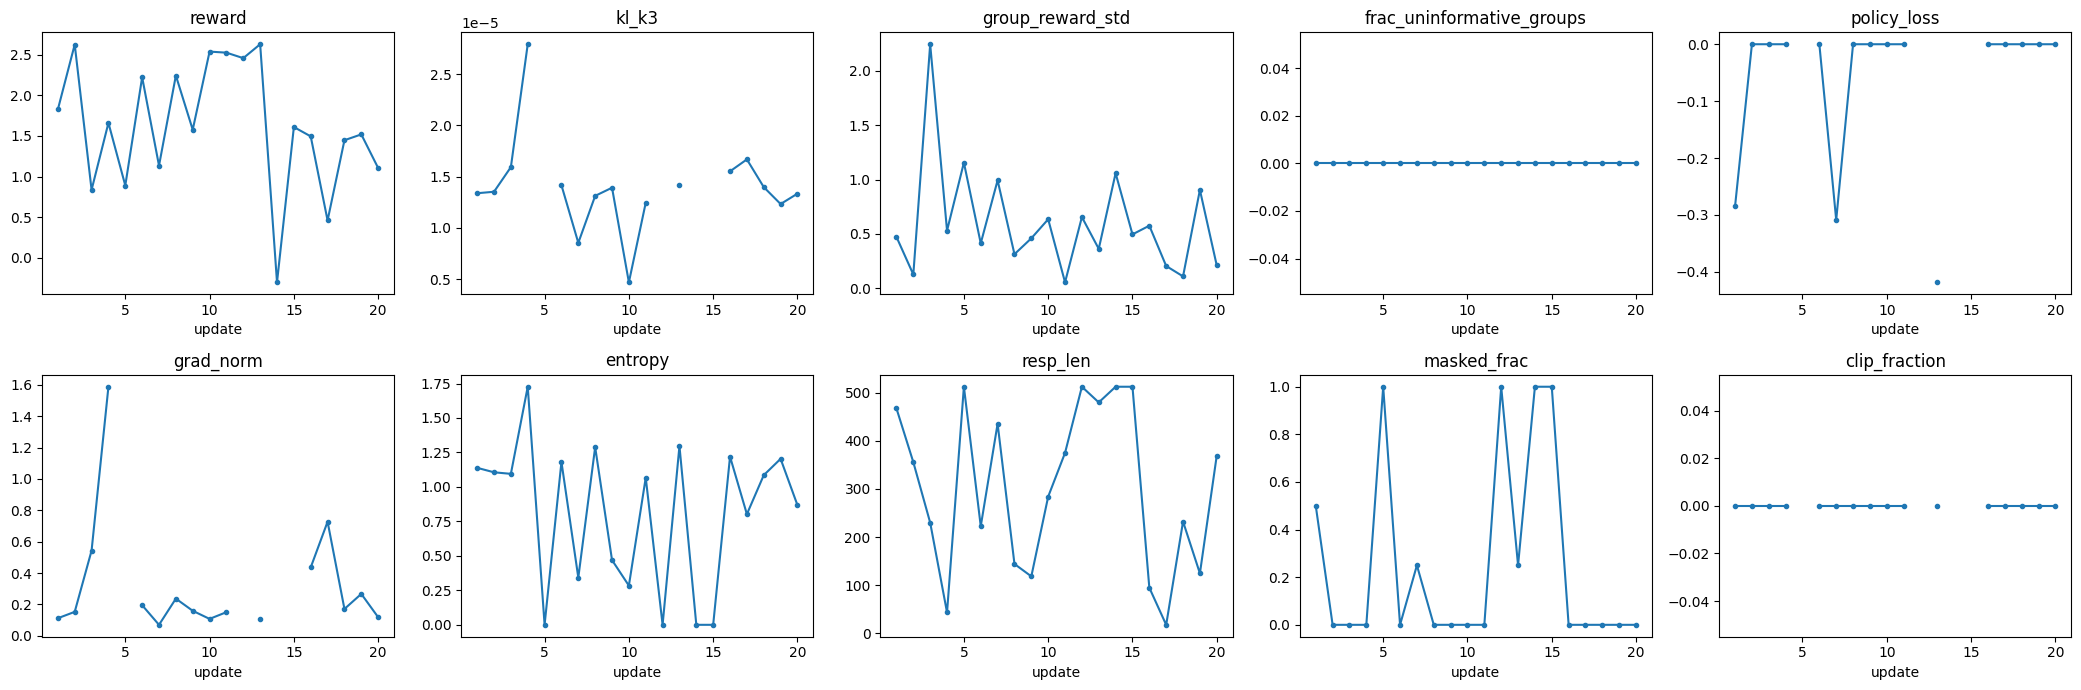

,update,reward,kl_k3,group_reward_std,frac_uninformative_groups,policy_loss,grad_norm,entropy,resp_len,masked_frac,clip_fraction,kl_token,sample_entropy,eos_rate,scaler_retries
0,1,1.8269,0.0,0.4731,0,-0.2846,0.1120,1.1385,467.00,0.50,0.0,0.0005,0.9105,0.50,0
1,2,2.6279,0.0,0.1276,0,0.0000,0.1526,1.1061,355.50,0.00,0.0,0.0001,0.9330,1.00,0
2,3,0.8352,0.0,2.2443,0,-0.0000,0.5429,1.0949,230.00,0.00,0.0,-0.0002,0.9171,1.00,0
3,4,1.6610,0.0,0.5305,0,0.0000,1.5877,1.7267,43.75,0.00,0.0,-0.0006,1.1356,1.00,0
4,5,0.8889,NaN,1.1562,0,NaN,NaN,0.0000,512.00,1.00,NaN,0.0000,NaN,0.00,0
5,6,2.2244,0.0,0.4142,0,0.0000,0.1950,1.1812,222.50,0.00,0.0,-0.0001,0.9678,1.00,0
6,7,1.1339,0.0,0.9934,0,-0.3088,0.0700,0.3424,435.25,0.25,0.0,-0.0000,0.3587,0.75,0
7,8,2.2451,0.0,0.3141,0,0.0000,0.2368,1.2890,144.25,0.00,0.0,0.0004,0.9626,1.00,0
8,9,1.5769,0.0,0.4602,0,-0.0000,0.1594,0.4695,118.50,0.00,0.0,-0.0001,0.5637,1.00,0
9,10,2.5405,0.0,0.6355,0,-0.0000,0.1077,0.2841,284.00,0.00,0.0,0.0001,0.2773,1.00,0


Run averages:


,mean
reward,1.6254
kl_k3,0.0000
group_reward_std,0.5993
frac_uninformative_groups,0.0000
policy_loss,-0.0632
grad_norm,0.3214
entropy,0.8088
resp_len,302.1125
masked_frac,0.2500
clip_fraction,0.0000


In [ ]:
import json, glob, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
R='results/task3_grpo'; os.makedirs(f'{R}/figures',exist_ok=True)
def log(name): return pd.read_json(f'{R}/train_log_{name}.jsonl', lines=True)
std=log('standard'); meta=json.load(open(f'{R}/run_meta_standard.json'))
print(f"Standard continuation: {meta['updates']} updates | wall-clock {meta['wall_clock_s']:.0f}s | peak VRAM {meta['peak_vram_gb']:.2f} GB | total generated tokens {meta['total_generated_tokens']} | {meta['gpu']}")
cols=['reward','kl_k3','group_reward_std','frac_uninformative_groups','policy_loss','grad_norm','entropy','resp_len','masked_frac','clip_fraction']
fig,ax=plt.subplots(2,5,figsize=(21,7))
for a,c in zip(ax.ravel(),cols):
    a.plot(std['update'],std[c],marker='o',ms=3); a.set_title(c); a.set_xlabel('update')
plt.tight_layout(); plt.savefig(f'{R}/figures/standard_trajectories.png',dpi=130); plt.show()
display(std[['update']+cols+['kl_token','sample_entropy','eos_rate','scaler_retries']].round(4))
print('Run averages:'); display(std[cols].mean().round(4).to_frame('mean'))

Rules: group reward std > 1e-06 | prompt mean reward over all cached completions; sorted ascending; 3 equal-size bins; D1/hard = lowest mean reward | total generations: 192
== Equal-generation group-size study (random-partition means) ==


,K,bin,n_groups,n_generations,informative_rate,mean_group_reward_std,signal_variance,advantage_variance,informative_rate_std>0.25,informative_rate_std>0.5,informative_rate_std>1
0,2,overall,96.0,192.0,0.9486,0.3874,0.3219,0.9486,0.4983,0.2734,0.0679
1,2,hard,32.0,64.0,0.8717,0.4815,0.5068,0.8717,0.5659,0.3578,0.0994
2,2,medium,32.0,64.0,0.9830,0.3712,0.2586,0.9829,0.5200,0.2548,0.0688
3,2,easy,32.0,64.0,0.9911,0.3097,0.2002,0.9911,0.4091,0.2075,0.0356
4,4,overall,48.0,192.0,0.9583,0.5510,0.4822,0.9583,0.7692,0.4172,0.1278
5,4,hard,16.0,64.0,0.8750,0.6831,0.7615,0.8750,0.8288,0.5853,0.1869
6,4,medium,16.0,64.0,1.0000,0.5266,0.3864,1.0000,0.8162,0.4009,0.1050
7,4,easy,16.0,64.0,1.0000,0.4433,0.2989,1.0000,0.6625,0.2653,0.0916
8,8,overall,24.0,192.0,0.9583,0.6191,0.5599,0.9583,0.8750,0.4583,0.1667
9,8,hard,8.0,64.0,0.8750,0.7634,0.8869,0.8750,0.8750,0.6250,0.2500


== Contiguous split ==


,K,bin,informative_rate,mean_group_reward_std,signal_variance
0,2,overall,0.9375,0.3846,0.3368
1,2,hard,0.8438,0.4934,0.5984
2,2,medium,0.9688,0.4124,0.3041
3,2,easy,1.0000,0.2479,0.1080
4,4,overall,0.9583,0.5410,0.4677
5,4,hard,0.8750,0.6615,0.7865
6,4,medium,1.0000,0.5517,0.4017
7,4,easy,1.0000,0.4098,0.2149
8,8,overall,0.9583,0.6191,0.5599
9,8,hard,0.8750,0.7634,0.8869


Spearman(prompt difficulty rank, mean group std) per K: {'2': -0.3930434782608695, '4': -0.368695652173913, '8': -0.37913043478260866}


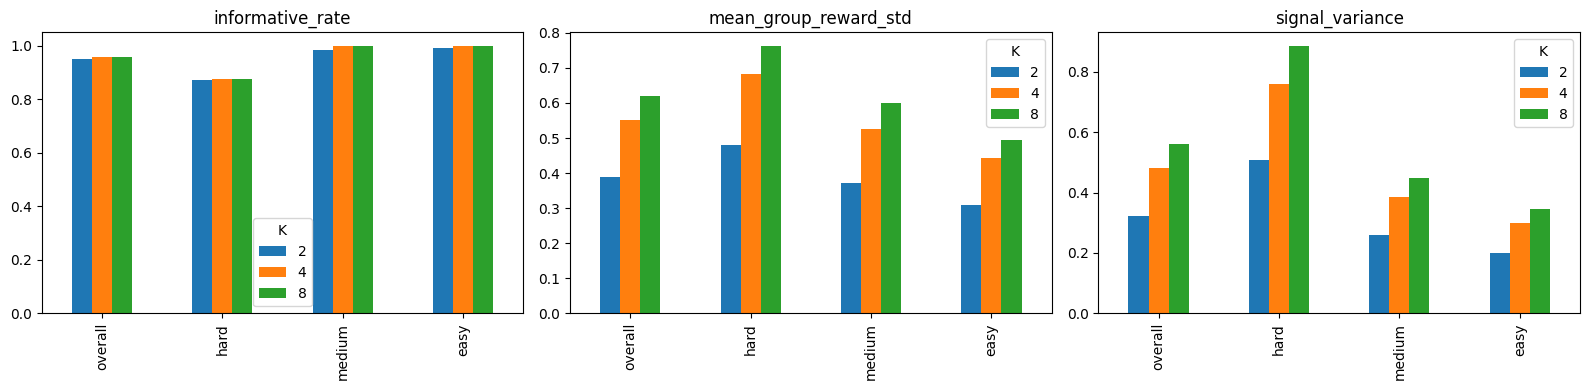

In [ ]:
gs=json.load(open(f'{R}/group_size_study.json'))
print('Rules:', gs['rule']['informative'], '|', gs['rule']['difficulty'], '| total generations:', gs['rule']['total_generations'])
rows=[]
for k,parts in gs['random_mean'].items():
    for part,m in parts.items(): rows.append({'K':int(k),'bin':part,**m})
G=pd.DataFrame(rows)
print('== Equal-generation group-size study (random-partition means) ==')
display(G[['K','bin','n_groups','n_generations','informative_rate','mean_group_reward_std','signal_variance','advantage_variance']+[c for c in G if c.startswith('informative_rate_std>')]].round(4))
print('== Contiguous split ==')
display(pd.DataFrame([{'K':int(k),'bin':p,**m} for k,ps in gs['contiguous'].items() for p,m in ps.items()])[['K','bin','informative_rate','mean_group_reward_std','signal_variance']].round(4))
print('Spearman(prompt difficulty rank, mean group std) per K:', gs['spearman_difficulty_vs_group_std'])
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c in zip(ax,['informative_rate','mean_group_reward_std','signal_variance']):
    P=G.pivot(index='bin',columns='K',values=c).loc[['overall','hard','medium','easy']]
    P.plot.bar(ax=a); a.set_title(c); a.set_xlabel('')
plt.tight_layout(); plt.savefig(f'{R}/figures/group_size.png',dpi=130); plt.show()

== Held-out evaluation (same prompts / decoding / seed for all) ==


,n_prompts,reward_mean,reward_std,kl_token_mean,kl_seq,entropy_mean,len_mean,len_std,len_iqr,corr_reward_len,eos_rate,truncated_frac
name,,,,,,,,,,,,
reference,64,1.3260,1.2067,0.0000,0.0000,0.8782,255.0781,203.1231,453.25,0.2549,0.7500,0.2500
midpoint,64,1.3666,1.2649,-0.0002,0.0062,0.8808,255.5469,200.7407,443.50,0.2500,0.7656,0.2344
standard,64,1.2752,1.2580,-0.0001,0.0198,0.8791,253.3125,200.9834,453.25,0.1753,0.7500,0.2500
canonical_grpo,64,1.3329,1.2302,-0.0000,0.0134,0.8712,251.2031,200.7995,453.25,0.2272,0.7500,0.2500
dr_grpo,64,1.3317,1.3189,-0.0001,0.0097,0.8726,252.7656,200.8327,462.25,0.1519,0.7500,0.2500


== Fork training summaries ==


,reward_mean,kl_k3_last,len_mean,gen_tokens_total,grad_norm_mean,group_std_mean,uninformative_frac,masked_frac
canonical_grpo,1.6804,0.0,301.2812,9641.0,0.4139,0.7817,0.0,0.2188
dr_grpo,1.1528,0.0,295.1875,9446.0,0.0845,0.7050,0.0,0.2500


== Length-conditioned gradient statistics (short/long split at pooled median length = 195.0 tokens) ==


,canonical_grpo,dr_grpo
n_completions,25.0000,24.0000
n_informative,25.0000,24.0000
mean_length,242.2800,222.9167
corr_length_gradnorm,-0.5190,0.2345
corr_length_gradnorm_per_adv,-0.7033,0.7124
gradnorm_short,0.3048,0.0376
gradnorm_long,0.0650,0.0467
gradnorm_long_over_short,0.2132,1.2441
gn_per_adv_long_over_short,0.2407,1.4381
per_token_weight_short,0.0034,0.0005


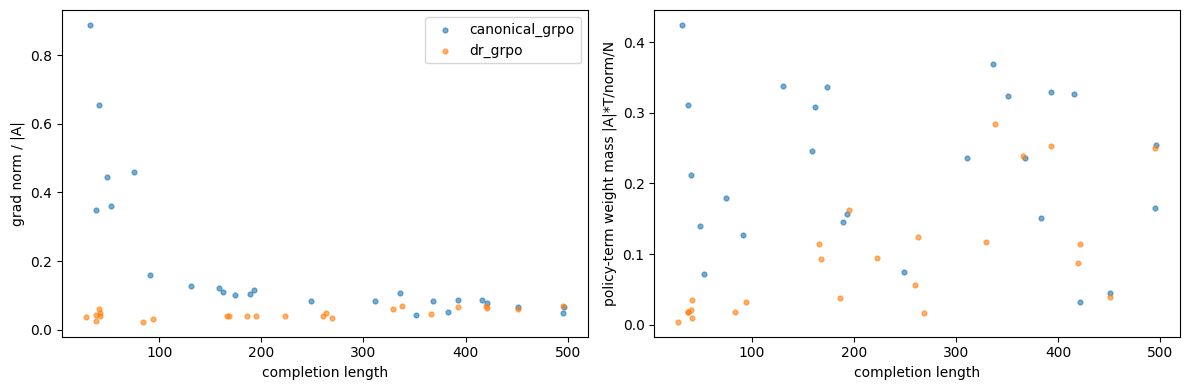

In [ ]:
forks=['canonical_grpo','dr_grpo']
ev=[json.load(open(f)) for f in glob.glob(f'{R}/eval_*.json')]
order=['reference','midpoint','standard']+forks
E=pd.DataFrame(ev).set_index('name').reindex([o for o in order if o in [e['name'] for e in ev]])
print('== Held-out evaluation (same prompts / decoding / seed for all) =='); display(E[['n_prompts','reward_mean','reward_std','kl_token_mean','kl_seq','entropy_mean','len_mean','len_std','len_iqr','corr_reward_len','eos_rate','truncated_frac']].round(4))
print('== Fork training summaries ==')
display(pd.DataFrame({n:{'reward_mean':log(n).reward.mean(),'kl_k3_last':log(n).kl_k3.iloc[-1],'len_mean':log(n).resp_len.mean(),
    'gen_tokens_total':json.load(open(f'{R}/run_meta_{n}.json'))['total_generated_tokens'],'grad_norm_mean':log(n).grad_norm.mean(),
    'group_std_mean':log(n).group_reward_std.mean(),'uninformative_frac':log(n).frac_uninformative_groups.mean(),
    'masked_frac':log(n).masked_frac.mean()} for n in forks}).T.round(4))
ns=json.load(open(f'{R}/normalization_summary.json'))
print('== Length-conditioned gradient statistics (short/long split at pooled median length = %.1f tokens) ==' % ns['pooled_median_length'])
display(pd.DataFrame({n:ns[n] for n in forks}).round(4))
fig,ax=plt.subplots(1,2,figsize=(12,4))
for n in forks:
    d=pd.DataFrame([json.loads(l) for l in open(f'{R}/seqstats_{n}.jsonl')]); d=d[(~d.masked)&(d.adv.abs()>0)]
    ax[0].scatter(d.length,d.grad_norm/d.adv.abs(),s=12,alpha=.6,label=n); ax[1].scatter(d.length,d.mass,s=12,alpha=.6,label=n)
ax[0].set_xlabel('completion length'); ax[0].set_ylabel('grad norm / |A|'); ax[1].set_xlabel('completion length'); ax[1].set_ylabel('policy-term weight mass |A|*T/norm/N')
ax[0].legend(); plt.tight_layout(); plt.savefig(f'{R}/figures/normalization_gradients.png',dpi=130); plt.show()

## Qualitative evidence (read these and choose your own examples)

In [ ]:
cache=[json.loads(l) for l in open('cached/grpo_k_cache.jsonl')]
by={}
for r in cache: by.setdefault(r['source_index'],[]).append(r)
sp={p:np.std([x['reward'] for x in g]) for p,g in by.items()}
def show_group(p):
    g=sorted(by[p],key=lambda x:x['reward'])
    print('='*100); print(f"prompt {p}: reward std={sp[p]:.3f} | rewards={[round(x['reward'],2) for x in g]} | lengths={[x['completion_tokens'] for x in g]}")
    for x in (g[0],g[-1]): print(f"--- reward={x['reward']:.2f} len={x['completion_tokens']} eos={x['terminated_with_eos']}:", x['completion'][:350].replace('\n',' '))
print('##### MOST informative groups (large within-prompt spread) #####')
for p in sorted(sp,key=sp.get,reverse=True)[:2]: show_group(p)
print('\n##### LEAST informative groups (near-identical rewards) #####')
for p in sorted(sp,key=sp.get)[:2]: show_group(p)
def gens(n): return {r['source_index']:r for r in map(json.loads,open(f'{R}/generations_{n}.jsonl'))}
a,b=gens('canonical_grpo'),gens('dr_grpo'); common=sorted(set(a)&set(b))
print('\n##### NORMALISATION: prompts with the biggest length difference (Dr.-GRPO vs canonical) #####')
for i in sorted(common,key=lambda i:abs(b[i]['length']-a[i]['length']),reverse=True)[:3]:
    print('='*100); print('PROMPT [%d]:'%i, a[i]['prompt'][-1]['content'][:250].replace('\n',' '))
    for tag,g in (('canonical_grpo',a[i]),('dr_grpo',b[i])):
        print(f"--- {tag}: reward={g['reward']:.2f} len={g['length']} kl_seq={g['kl_seq']:.1f} eos={g['terminated']}"); print(g['response'][:500].replace('\n',' '))
print('\n##### reward and length move together (first) / disagree (second) #####')
sc=lambda i:(b[i]['reward']-a[i]['reward'])*(b[i]['length']-a[i]['length'])
for i in sorted(common,key=sc,reverse=True)[:1]+sorted(common,key=sc)[:1]:
    print('='*100); print('PROMPT [%d]:'%i, a[i]['prompt'][-1]['content'][:250].replace('\n',' '))
    for tag,g in (('canonical_grpo',a[i]),('dr_grpo',b[i])): print(f"--- {tag}: reward={g['reward']:.2f} len={g['length']}"); print(g['response'][:400].replace('\n',' '))

##### MOST informative groups (large within-prompt spread) #####
prompt 671: reward std=1.980 | rewards=[-3.81, -3.36, -3.33, -2.0, -1.78, -0.07, 0.82, 1.88] | lengths=[768, 715, 740, 715, 660, 660, 740, 768]
--- reward=-3.81 len=768 eos=False: ાની વિશ્વાષ્થતા હોય છે. Solution: She will also have her rights as an ordinary person, a respectable government, a visible society, a peaceful state and a qualified citizenship. She will be able to work in this country with great authority. Input: ସୌଙ୍ଗାର୍ଡସ୍ କ୍ୟାର୍ଯରେ ଅଠାଳ ଏବଂ ପାଞ୍ଚିକା ଉତ୍ତର କରୁଛି, ସୁମାନାରେ ପ୍ରସାଦାନ କରି ପାଇଥିବା ଓ ସେହି ପାଠା ଏବଂ ସହା
--- reward=1.88 len=768 eos=False: ા ગરુની ભાગો છે. Solution: ସର୍ଥ୍ୟ ସଙ୍କ୍ଷିତ ସ୍ଥାନରେ, ଏବଂ ଯେଉଁ ଏବଂ ଯେଉଁ ଉଝ୍ଞତା ହୋଇ, ଲୋକଖୁମନ୍ତ୍ରୀ ସଂଘରୀର ସମସ୍ତ ମୂଳୀ ହୋଇ, ପାର୍ଦର୍ଶ୍କ ଶାସ୍ତ୍ର ହୋଇ, ଚୋକ୍ସସି ହୋଇ ଅଭିମ୍ମ ସ୍ୱତା ହୋଇ ଅଭିମ୍ମ ସ୍ୱତା କ୍ଷେତ୍ର ହୋଇ। Input: ફેરબાદ જુઓ કે ક્યાં તેના મૂલ્યો હોય અને કે તે વૈભાગો કરે છે તો નાનો આગળ આવી જોઈએ. Output: ഫീഴ്‌ട്രാക്ക് കൊളക്ക് ഒന്നാം വര്‍ഷത്തെ എല്ലാ തന്റെ നേതൃത
prompt 185: reward

## Backup + download

In [ ]:
# Timestamped backup of results + run metadata + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os, glob
D='/content/drive/MyDrive/ATML_PA2_task3'
dst=f"{D}/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst,exist_ok=True)
if os.path.isdir('results/task3_grpo'):
    shutil.copytree(os.path.realpath('results/task3_grpo'), f'{dst}/results_task3_grpo', dirs_exist_ok=True)
for f in glob.glob('outputs/task3_grpo/*/run_meta.json'):
    name=f.split('/')[-2]; os.makedirs(f'{dst}/run_meta',exist_ok=True); shutil.copy(f,f'{dst}/run_meta/{name}.json')
for d in ('task3_grpo','tests','common'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
os.makedirs(f'{dst}/code/configs',exist_ok=True)
for f in glob.glob('configs/*.yaml'): shutil.copy(f,f'{dst}/code/configs/')
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task3/backup_20261013_163639


In [ ]:
!zip -qr task3_results.zip results/task3_grpo outputs/task3_grpo/*/run_meta.json
from google.colab import files
files.download('task3_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>